# 02 — Statistical analysis and modelling

Five business questions, each answered with a method suited to it and **checked against a
baseline** on data the model never saw:

1. **Hypothesis tests:** which commonly held beliefs about these customers survive a formal test?
2. **Segmentation:** what kinds of customers are there? (RFM rules and k-means)
3. **Customer lifetime value:** what is each customer worth over the next 12 months? (BG/NBD + Gamma-Gamma)
4. **Purchase propensity:** who will buy again in the next 90 days? (out-of-time validated classifier)
5. **Forecasting:** how much revenue next quarter? (benchmarked against seasonal naive)

The computation lives in `src/retail/analysis/` and runs with `retail analyse`. This notebook
reads its outputs from the warehouse and explains them.

In [1]:
import json

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

from retail import config

con = duckdb.connect(str(config.DB_PATH), read_only=True)
q = lambda sql: con.execute(sql).df()  # noqa: E731
metrics = json.loads((config.REPORTS / "metrics.json").read_text())

COBALT, AMBER, TEAL, GREY = "#5A6CF0", "#E39B2D", "#2BB39E", "#8A93A3"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
gbp = mtick.FuncFormatter(lambda x, _: f"£{x/1e3:,.0f}k" if abs(x) >= 1e3 else f"£{x:,.0f}")
pd.set_option("display.max_colwidth", 120)


def save(fig, name):
    fig.savefig(config.FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Hypothesis tests

Each test reports an **effect size with a 95% confidence interval** as well as a p-value. With
thousands of customers almost any difference is "significant", so the useful question is
*how big* the difference is. Five tests run on the same data, so p-values are **Holm-corrected**.

In [2]:
tests = q("select * from analytics.hypothesis_tests")
tests[["question", "method", "effect", "ci_low", "ci_high", "p_holm", "significant"]].round(4)

,question,method,effect,ci_low,ci_high,p_holm,significant
0,Do customers acquired in Nov-Dec (gift season) return at a different rate within 180 days?,Two-proportion z-test; Newcombe CI on the difference,65.7% vs 58.5% return rate,0.0414,0.1013,0.0000,True
1,Do international customers place larger orders than UK customers?,Mann-Whitney U (order values are heavily skewed); bootstrap CI of median difference,median £418 vs £299; P(intl > UK) = 0.63,102.1298,139.4010,0.0000,True
2,Does daily revenue differ by day of week?,Kruskal-Wallis H test; epsilon-squared effect size,epsilon² = 0.207; Saturday trading is almost nil,NaN,NaN,0.0000,True
3,Did average daily revenue grow year over year (Jan-Nov 2011 vs 2010)?,Welch's t-test; bootstrap CI of the mean difference,"£29,887 vs £29,241 per trading day (+2.2%)",-1714.2297,2885.1829,0.5795,False
4,Do customers who return items spend more overall than those who never do?,Mann-Whitney U; bootstrap CI of median difference,"median lifetime spend £2,072 vs £479",1483.1505,1719.4407,0.0000,True


**Reading the results**

* **Gift-season customers are *more* loyal, not less.** The common assumption is that Nov–Dec
  customers are one-off buyers. Here they come back within 180 days *more* often (about 7 points
  higher). For a wholesaler, Q4 acquisition is worth investing in, not discounting.
* **International orders are bigger** (higher median basket): international customers are
  mostly stockists ordering in bulk. A worthwhile segment for account management.
* **Weekday matters a lot** (large Kruskal-Wallis effect): this is a weekday B2B business,
  so staffing and email sends should follow that rhythm.
* **Year-over-year growth is *not* significant.** Average daily revenue in Jan–Nov 2011 is only
  about 2% above 2010, and the confidence interval spans zero. The business is flat. That doesn't
  show up on a monthly revenue chart, which looks noisy, and it is the most important finding
  for the owner.
* **Customers who return items are the *best* customers** (median lifetime spend ~4x higher).
  Returns come with volume, so a "high returner" flag shouldn't be used to deprioritise accounts.

## 2. Segmentation

**RFM** scores every customer 1–5 on Recency, Frequency and Monetary value (quintiles) and maps
the combinations to named segments a marketing team can act on.

In [3]:
seg = q("select * from analytics.segment_summary")
seg.style.format({"revenue": "£{:,.0f}", "monetary": "£{:,.0f}", "revenue_share": "{:.1%}"})

,segment,customers,recency_days,frequency,monetary,revenue,revenue_share
0,Champions,1304,16.000000,11.000000,"£3,888","£11,041,942",69.2%
1,Loyal,1203,67.000000,4.000000,"£1,267","£2,509,518",15.7%
2,At risk,454,290.000000,4.000000,"£1,255","£951,764",6.0%
3,Lost,1102,536.000000,1.000000,£309,"£506,476",3.2%
4,Promising,781,64.000000,2.000000,£417,"£365,852",2.3%
5,Can't lose,68,469.000000,6.000000,"£2,320","£272,356",1.7%
6,Needs attention,715,313.000000,1.000000,£316,"£267,788",1.7%
7,New,221,28.000000,1.000000,£209,"£50,193",0.3%


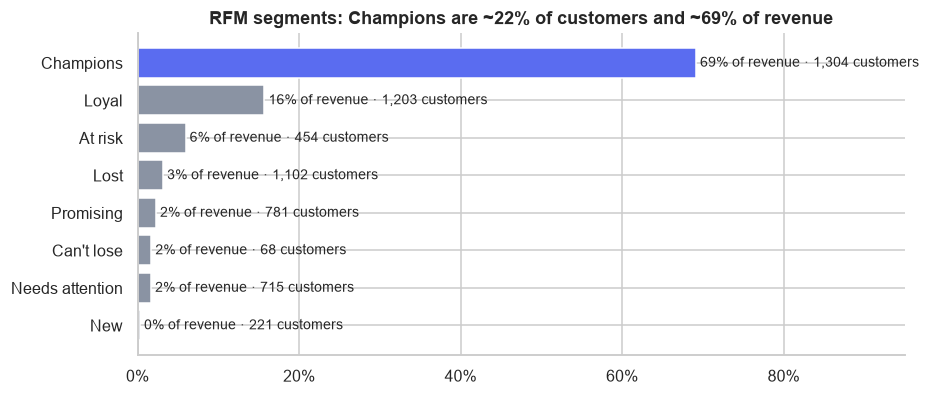

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
s = seg.sort_values("revenue")
ax.barh(s["segment"], s["revenue_share"], color=[COBALT if x == "Champions" else GREY for x in s["segment"]])
for y, (share, n) in enumerate(zip(s["revenue_share"], s["customers"], strict=True)):
    ax.text(share + 0.005, y, f"{share:.0%} of revenue · {n:,} customers", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 0.95)
ax.set_title("RFM segments: Champions are ~22% of customers and ~69% of revenue")
save(fig, "model_rfm_segments")

**k-means** on log-scaled R, F and M checks how many groups the data itself supports.
Silhouette is highest at k = 2 (an "active vs lapsed" split), which isn't much use to a
marketing team. k = 4 is the best of the actionable options and is within 0.1 of the maximum.

,cluster,customers,recency_days,frequency,monetary,revenue,revenue_share
0,0,1106,15.0,13.0,5088.075,11328639.20,0.7096
1,1,1468,157.0,5.0,1576.910,2942457.13,0.1843
2,2,1220,23.0,3.0,706.545,998092.67,0.0625
3,3,2054,399.0,1.0,290.735,696700.45,0.0436


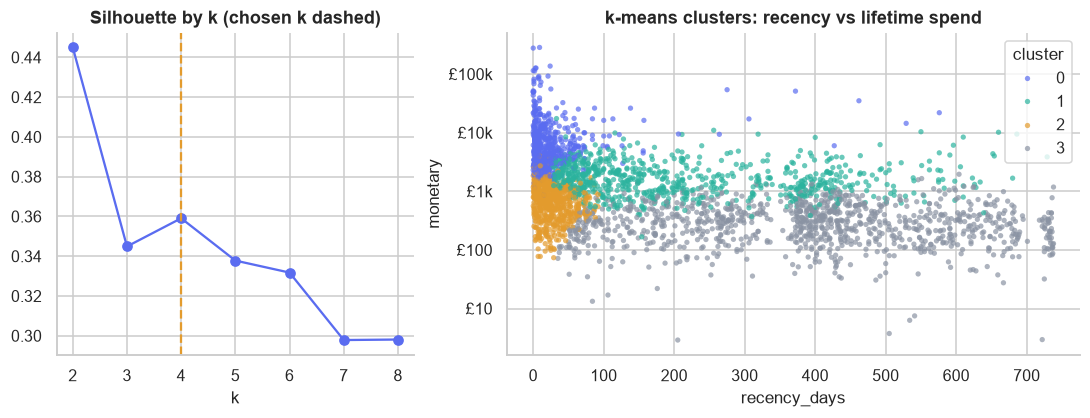

In [5]:
sil = q("select * from analytics.kmeans_silhouette")
clusters = q("select * from analytics.cluster_summary order by cluster")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].plot(sil["k"], sil["silhouette"], marker="o", color=COBALT)
axes[0].axvline(metrics["segmentation"]["k"], color=AMBER, ls="--")
axes[0].set_title("Silhouette by k (chosen k dashed)")
axes[0].set_xlabel("k")
cs = q("select * from analytics.customer_segments")
sns.scatterplot(data=cs.sample(3000, random_state=1), x="recency_days", y="monetary", hue="cluster",
                palette=[COBALT, TEAL, AMBER, GREY], s=12, alpha=0.7, ax=axes[1], linewidth=0)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(gbp)
axes[1].set_title("k-means clusters: recency vs lifetime spend")
save(fig, "model_kmeans")
clusters

## 3. Customer lifetime value: BG/NBD + Gamma-Gamma

The **BG/NBD** model (Fader, Hardie & Lee, 2005) treats each customer as buying at their own
Poisson rate while "alive", with a chance of silently dropping out after each purchase. That
fits non-contractual businesses like this one, where customers never tell you they've left.
**Gamma-Gamma** models how much each purchase is worth. Both are implemented from the
papers' likelihoods with `scipy.optimize` (see `clv.py`), not taken from a library.

**Validation:** fit on data up to June 2011, predict the number of purchases in the next
26 weeks, then compare with what actually happened.

In [6]:
v = metrics["clv"]["validation"]
pd.DataFrame({
    "": ["total purchases in holdout", "per-customer MAE", "correlation with actual"],
    "actual": [v["actual_total"], None, None],
    "BG/NBD": [round(v["predicted_total"]), round(v["mae_model"], 2), round(v["corr_model"], 3)],
    "baseline (historical rate)": [round(v["baseline_total"]), round(v["mae_baseline"], 2), None],
})

,,actual,BG/NBD,baseline (historical rate)
0,total purchases in holdout,7712.0,7580.000,12997.00
1,per-customer MAE,NaN,1.040,1.67
2,correlation with actual,NaN,0.849,NaN


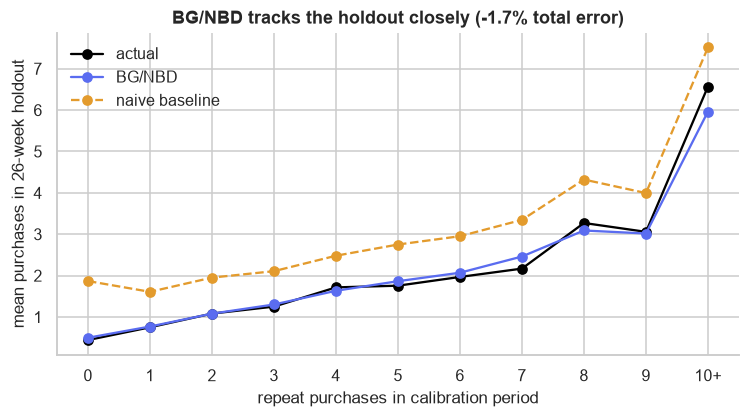

In [7]:
cal = q("select * from analytics.clv_calibration")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(cal["x_bucket"], cal["x_holdout"], marker="o", color="black", label="actual")
ax.plot(cal["x_bucket"], cal["pred_holdout"], marker="o", color=COBALT, label="BG/NBD")
ax.plot(cal["x_bucket"], cal["baseline_holdout"], marker="o", color=AMBER, ls="--", label="naive baseline")
ax.set_xticks(range(11), [*map(str, range(10)), "10+"])
ax.set_xlabel("repeat purchases in calibration period")
ax.set_ylabel("mean purchases in 26-week holdout")
ax.set_title(f"BG/NBD tracks the holdout closely ({v['predicted_total'] / v['actual_total'] - 1:+.1%} total error)")
ax.legend(frameon=False)
save(fig, "model_clv_validation")

The naive "keep buying at your historical rate" baseline **overpredicts by about 70%**: it
assumes everyone is still a customer. BG/NBD's dropout process is what corrects this. Its
per-customer error is ~38% lower.

Refit on the full history, the model gives each customer a 12-month expected value and a
probability of still being active (`p_alive`):

Gamma-Gamma assumption check: corr(frequency, spend) = 0.18 (weak, acceptable)


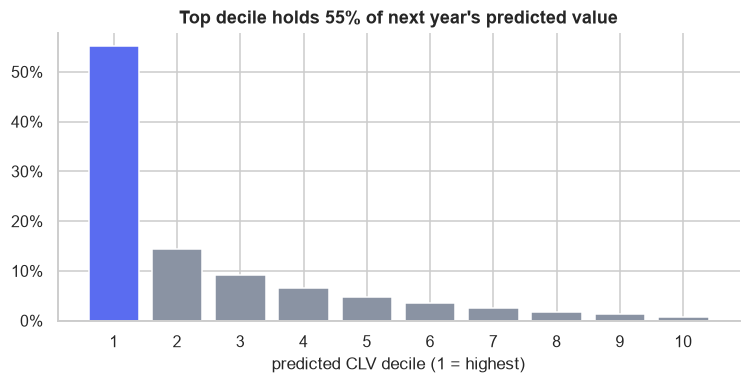

In [8]:
clv = q("select * from analytics.customer_clv")
dec = clv.groupby("clv_decile").agg(customers=("customer_key", "size"), clv_12m=("clv_12m", "sum"),
                                     median_p_alive=("p_alive", "median")).reset_index()
dec["share"] = dec["clv_12m"] / dec["clv_12m"].sum()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(dec["clv_decile"], dec["share"], color=[COBALT] + [GREY] * 9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xticks(range(1, 11))
ax.set_xlabel("predicted CLV decile (1 = highest)")
ax.set_title(f"Top decile holds {metrics['clv']['top_decile_share']:.0%} of next year's predicted value")
save(fig, "model_clv_deciles")
print(f"Gamma-Gamma assumption check: corr(frequency, spend) = {metrics['clv']['params']['freq_spend_corr']:.2f} (weak, acceptable)")

## 4. Purchase propensity: who buys again in the next 90 days?

**Leakage control:** features are computed only from data up to a cutoff date; the label is
whether the customer bought in the 90 days *after* it. Training stacks four quarterly cutoffs
(Sep 2010 – Jun 2011). The test set is the **most recent** cutoff (Sep 2011), so this is an
out-of-time test, the way the model would actually be used.

In [9]:
pm = metrics["propensity"]
print(f"train rows: {pm['meta']['train_rows']:,} | test rows: {pm['meta']['test_rows']:,} | "
      f"test base rate: {pm['meta']['base_rate_test']:.1%}")
q("select * from analytics.propensity_scores").round(3)

train rows: 17,214 | test rows: 5,253 | test base rate: 43.6%


,model,roc_auc,pr_auc,brier,lift_top_decile
0,recency rule,0.763,0.686,NaN,1.780
1,logistic regression,0.804,0.779,0.190,2.130
2,gradient boosting,0.801,0.778,0.193,2.138


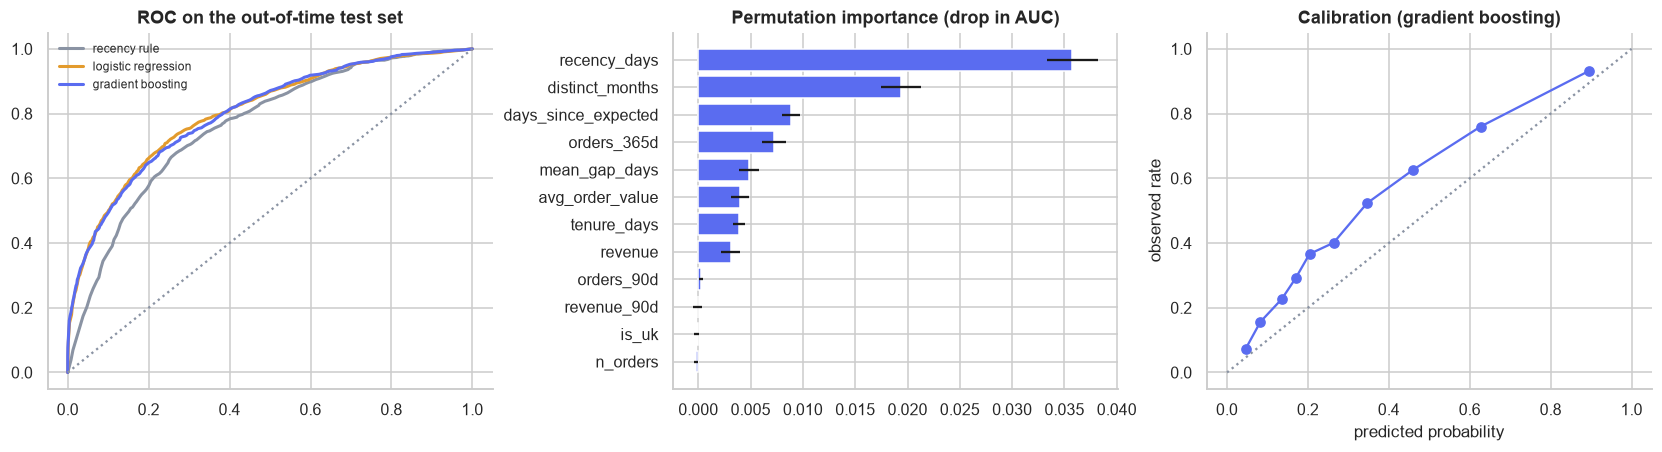

In [10]:
roc = q("select * from analytics.propensity_roc")
imp = q("select * from analytics.propensity_importance")
calib = q("select * from analytics.propensity_calibration")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for (name, d), c in zip(roc.groupby("model", sort=False), [GREY, AMBER, COBALT], strict=True):
    axes[0].plot(d["fpr"], d["tpr"], color=c, label=name, lw=2)
axes[0].plot([0, 1], [0, 1], color=GREY, ls=":")
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("ROC on the out-of-time test set")
axes[1].barh(imp["feature"][::-1], imp["importance"][::-1], xerr=imp["std"][::-1], color=COBALT)
axes[1].set_title("Permutation importance (drop in AUC)")
axes[2].plot(calib["mean_predicted"], calib["fraction_positive"], marker="o", color=COBALT)
axes[2].plot([0, 1], [0, 1], color=GREY, ls=":")
axes[2].set_title("Calibration (gradient boosting)")
axes[2].set_xlabel("predicted probability")
axes[2].set_ylabel("observed rate")
save(fig, "model_propensity")

* Both models beat the **recency-only rule** (what most teams use by default) by about 4 AUC
  points, and reach a 2.1x lift in the top-scored 10% of customers (recency rule: 1.8x).
* **Logistic regression matches gradient boosting.** With well-engineered features the simpler,
  more explainable model is just as good, and that's the one I'd recommend shipping.
* The model **systematically underestimates** purchase probability (curve above the diagonal): the test
  quarter is the pre-Christmas peak, when everyone buys more. If the probabilities themselves
  drive spend, they should be recalibrated each season (isotonic / Platt scaling).
* The top features are recency, **distinct active months** (habit) and **days overdue relative
  to the customer's own buying cycle**, a feature that came out of the EDA's B2B finding.

## 5. Forecasting weekly revenue

Only two years of weekly data exist, which is too short for a classic 52-week Holt-Winters
season. Annual seasonality is modelled with **Fourier terms** (plus trend and a Christmas
closure dummy) in a regression and a SARIMAX. Every model is scored on the last **12 weeks**
(the 2011 peak season) against naive baselines, using **MASE** (< 1 means better than
seasonal naive).

In [11]:
scores = q("select * from analytics.forecast_scores")
scores.round(3)

,model,mase,mape,total_error_pct,coverage_80
0,ensemble (growth-naive + fourier),0.961,0.103,0.031,NaN
1,seasonal naive,1.010,0.110,-0.020,NaN
2,fourier regression,1.202,0.118,-0.046,0.833
3,seasonal naive + growth,1.259,0.134,0.107,NaN
4,SARIMAX + fourier,2.142,0.213,0.168,0.500
5,naive (last week),2.960,0.273,-0.291,NaN


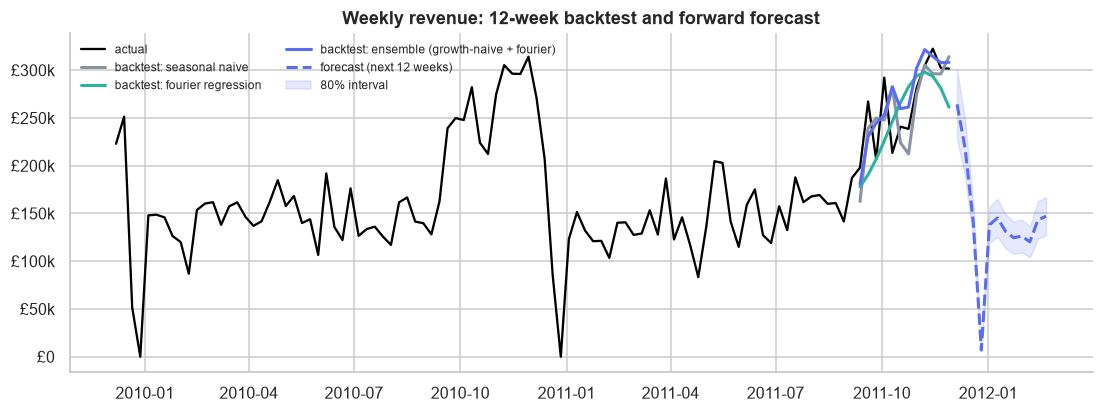

In [12]:
hist = q("select * from analytics.weekly_revenue")
bt = q("select * from analytics.forecast_backtest")
fut = q("select * from analytics.forecast_future")
best = metrics["forecast"]["best_model"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hist["week_start"], hist["revenue"], color="black", lw=1.5, label="actual")
for name, c in [("seasonal naive", GREY), ("fourier regression", TEAL), (best, COBALT)]:
    d = bt[bt["model"] == name]
    ax.plot(d["week_start"], d["forecast"], color=c, lw=2, label=f"backtest: {name}")
ax.plot(fut["week_start"], fut["forecast"], color=COBALT, lw=2, ls="--", label="forecast (next 12 weeks)")
ax.fill_between(fut["week_start"], fut["lower"], fut["upper"], color=COBALT, alpha=0.15, label="80% interval")
ax.yaxis.set_major_formatter(gbp)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
ax.set_title("Weekly revenue: 12-week backtest and forward forecast")
save(fig, "model_forecast")

* The **seasonal naive** baseline is very hard to beat for a flat, strongly seasonal business,
  which matches the hypothesis test that found no year-over-year growth.
* SARIMAX, the most complex model, does **worst** of the seasonal models: it overfits two years
  of data.
* A **simple average of two structurally different models** (growth-adjusted seasonal naive +
  Fourier regression) gives the best MASE (< 1) and a total-quarter error of about 3%. Forecast
  combination is a well-established, robust result (M-competitions).
* Caveat, stated plainly: the ensemble was chosen *after* seeing holdout scores. A production
  setup would pick it with rolling-origin cross-validation instead.

## 6. Market basket: what sells together?

In [13]:
q("select * from analytics.market_basket limit 12")

,item_a,item_b,support,confidence_a_to_b,lift
0,STAR WOODEN CHRISTMAS DECORATION,HEART WOODEN CHRISTMAS DECORATION,0.0072,0.706,67.24
1,CHRISTMAS GINGHAM STAR,CHRISTMAS GINGHAM TREE,0.0073,0.699,67.02
2,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BATHROOM,0.0089,0.624,61.35
3,COFFEE MUG PEARS DESIGN,COFFEE MUG APPLES DESIGN,0.0075,0.753,55.07
4,CARD MOTORBIKE SANTA,CARD CHRISTMAS VILLAGE,0.0061,0.557,54.51
5,SMALL YELLOW BABUSHKA NOTEBOOK,SMALL RED BABUSHKA NOTEBOOK,0.0067,0.658,52.88
6,PINK POLKADOT PLATE,BLUE POLKADOT PLATE,0.0073,0.577,51.20
7,CHILDS BREAKFAST SET SPACEBOY,CHILDS BREAKFAST SET DOLLY GIRL,0.0079,0.627,51.11
8,SET OF 12 FAIRY CAKE BAKING CASES,SET OF 12 MINI LOAF BAKING CASES,0.0077,0.554,49.34
9,SET/6 TURQUOISE BUTTERFLY T-LIGHTS,SET/6 PINK BUTTERFLY T-LIGHTS,0.0067,0.621,49.15


The strongest rules (lift 50–70x) are **colour and design variants of the same product line**:
customers buy the set. In practice, that means "complete the set" recommendations on the
product page and bundled pricing for ranges.

---
## What I'd tell the business owner

1. **Revenue is flat year over year.** That's the headline, and the monthly chart hides it.
2. **About 22% of customers (Champions) drive 69% of revenue**, and the top CLV decile holds
   over half of next year's predicted value. Retention of this group is the main lever.
3. **A 90-day propensity score** finds about twice as many likely buyers in the top decile as
   random targeting. Use it to time the account team's outreach.
4. **Don't write off Q4 customers or "returners"**: both are more valuable than average.
5. **Plan stock and staff from the forecast** (±~10% weekly error), and expect the next quarter
   to look like the last one.

In [14]:
con.close()